# Spotify Listener Behaviour Analysis & Release-Window Advisor

**Goal:** find the **best day** and the **best time of day** to publish a track of a given **genre**.
**Model:** Random Forest Regression  |  **Encoding:** Label Encoding  |  **Dashboard:** Website (JSON/CSV export)

**Flow:** 4 Datasets → Cleaning → Feature Engineering → Best DAY (Spotify 2023 + Charts) → Best HOUR (Last.fm) → Random Forest → Release Score → Exports for Website

| Dataset | File | Used for |
|---|---|---|
| Spotify Most Streamed 2023 | `spotify_2023_tracks.csv` | Release-weekday performance, ANOVA, Random Forest |
| Last.fm 1K listening events | `lastfm_listening_sample.parquet` | 168-hour listening-activity matrix |
| Spotify historical charts | `spotify_chart_historical.csv` | Genre x weekday demand |
| Sample artist catalog | `sample_artist_releases.csv` | Your own catalog sanity-check |

> If a file is missing, a **synthetic stand-in with the exact same schema** is generated so the notebook always runs. Replace with the real files (put them next to the notebook) and re-run: the numbers update automatically. **Synthetic results are for pipeline testing only.**

## 1. Import Libraries

In [1]:
import os, ast, json, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sns.set_theme(style='whitegrid'); np.random.seed(42)
os.makedirs('outputs', exist_ok=True)

OUR_GENRE = 'Pop'          # <-- change to your genre: Pop, Hip-Hop/Rap, Rock, Electronic, R&B, Indie, Latin, K-Pop, Indian
DAYS = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']

## 2. Load Datasets
Real files are used if present; otherwise schema-identical synthetic data is created.

In [2]:
rng = np.random.default_rng(42)
GENRES = {'Pop':['pop','dance pop'],'Hip-Hop/Rap':['hip hop','rap'],'Rock':['rock','alternative rock'],
          'Electronic':['edm','house'],'R&B':['r&b','soul'],'Indie':['indie pop','indie rock'],
          'Latin':['reggaeton','latin pop'],'K-Pop':['k-pop'],'Indian':['bollywood','filmi']}

def synth_tracks(n=953):
    wd = rng.choice(7, n, p=[.07,.08,.09,.11,.42,.12,.11])           # Fri-heavy release habit
    year = rng.choice([2019,2020,2021,2022,2023], n, p=[.04,.06,.1,.3,.5])
    month = rng.integers(1,13,n); day = rng.integers(1,28,n)
    base = pd.to_datetime(dict(year=year,month=month,day=day))
    base = base + pd.to_timedelta((wd - base.dt.dayofweek) % 7, unit='D')   # force chosen weekday
    playlists = rng.lognormal(7.2,1.1,n).astype(int)
    charts = rng.integers(0,60,n)
    age = (pd.Timestamp('2023-12-01') - base).dt.days/365
    streams = np.exp(16.2 + .55*np.log(playlists) + .25*np.log1p(age) + .004*charts
                     + 0.06*(wd==4) + 0.03*(wd==3) + rng.normal(0,.55,n)).astype(np.int64)
    d = pd.DataFrame({'track_name':[f'Track {i}' for i in range(n)],'artist(s)_name':[f'Artist {i%300}' for i in range(n)],
        'artist_count':rng.choice([1,2,3],n,p=[.7,.22,.08]),'released_year':base.dt.year,'released_month':base.dt.month,
        'released_day':base.dt.day,'streams':streams.astype(str),'in_spotify_playlists':playlists,'in_spotify_charts':charts,
        'bpm':rng.integers(70,180,n),'danceability_%':rng.integers(30,95,n),'valence_%':rng.integers(10,95,n),
        'energy_%':rng.integers(20,95,n),'acousticness_%':rng.integers(0,90,n),'speechiness_%':rng.integers(2,40,n)})
    d.loc[575,'streams'] = 'BPM110KeyAMode Major'     # the known anomaly row
    return d

def synth_lastfm(n=500_000):
    h = np.arange(24)
    wk = np.exp(-((h-19)**2)/(2*4.5**2)) + .55*np.exp(-((h-11)**2)/(2*3**2)) + .12
    we = np.exp(-((h-21)**2)/(2*4.2**2)) + .45*np.exp(-((h-15)**2)/(2*4**2)) + .15
    P = np.array([wk]*5 + [we]*2); P = P*np.array([.95,1,1,1.03,1.0,1.12,1.0])[:,None]; P/=P.sum()
    cell = rng.choice(168, n, p=P.ravel()); dow, hour = cell//24, cell%24
    start = pd.Timestamp('2008-01-07')                                   # a Monday
    week = rng.integers(0,70,n)
    ts = start + pd.to_timedelta(week*7+dow, unit='D') + pd.to_timedelta(hour,unit='h') + pd.to_timedelta(rng.integers(0,3600,n),unit='s')
    return pd.DataFrame({'user_id':[f'user_{u:06d}' for u in rng.integers(1,1001,n)],'timestamp':ts,
        'artist_id':None,'artist_name':'Artist','track_id':None,'track_name':'Track'})

def synth_charts(n=100_000):
    fam = list(GENRES); gp = np.array([.3,.2,.1,.1,.07,.07,.06,.05,.05]); gp/=gp.sum()
    g = rng.choice(len(fam), n, p=gp)
    date = pd.Timestamp('2023-01-01') + pd.to_timedelta(rng.integers(0,700,n), unit='D')
    dow = date.dt.dayofweek if hasattr(date,'dt') else pd.DatetimeIndex(date).dayofweek
    wkend = {'Pop':.04,'Hip-Hop/Rap':.10,'Rock':-.02,'Electronic':.14,'R&B':.05,'Indie':.0,'Latin':.12,'K-Pop':.06,'Indian':.08}
    fri = {'Pop':.06,'Hip-Hop/Rap':.05,'Rock':.02,'Electronic':.08,'R&B':.05,'Indie':.03,'Latin':.06,'K-Pop':.04,'Indian':.07}
    eff = np.array([ (wkend[fam[i]] if d>=5 else 0) + (fri[fam[i]] if d==4 else 0) for i,d in zip(g,dow)])
    streams = (rng.lognormal(11.6,.7,n)*np.exp(eff)).astype(int)
    genres = [str(GENRES[fam[i]]) for i in g]
    return pd.DataFrame({'date':date,'country':rng.choice(['us','de','jp','in','global','br'],n),'position':rng.integers(1,201,n),
        'streams':streams,'track_id':[f'trk{i%5000:05d}' for i in range(n)],'artists':'Artist','artist_genres':genres,
        'duration':rng.integers(120000,320000,n)})

def synth_catalog(n=22):
    gl = rng.choice(['Pop','Indie','Electronic','Hip-Hop','Rock','R&B'], n)
    dt = pd.Timestamp('2024-01-01') + pd.to_timedelta(rng.integers(0,500,n), unit='D') + pd.to_timedelta(rng.choice([8,10,14,18,20,21],n), unit='h')
    return pd.DataFrame({'track_id':[f'RW{i+1:04d}' for i in range(n)],'track_title':[f'{g} Sample Track {i+1:02d}' for i,g in enumerate(gl)],
        'artist_name':[f'Artist {i}' for i in rng.integers(1,40,n)],'release_datetime_local':dt,'timezone':'Asia/Kolkata',
        'target_market':'India','streams_first_7_days':rng.integers(50_000,600_000,n),'save_count':rng.integers(20,200,n)})

def load(path, reader, fake):
    if os.path.exists(path): print('REAL      ', path); return reader(path), True
    print('SYNTHETIC ', path); return fake(), False

tracks,  real_t = load('spotify_2023_tracks.csv', lambda p: pd.read_csv(p, encoding='latin-1'), synth_tracks)
lastfm,  real_l = load('lastfm_listening_sample.parquet', pd.read_parquet, synth_lastfm)
charts,  real_c = load('spotify_chart_historical.csv', pd.read_csv, synth_charts)
catalog, real_k = load('sample_artist_releases.csv', pd.read_csv, synth_catalog)
USING_SYNTHETIC = not (real_t and real_l and real_c)
for n,d in [('tracks',tracks),('lastfm',lastfm),('charts',charts),('catalog',catalog)]: print(n, d.shape)
tracks.head()

SYNTHETIC  spotify_2023_tracks.csv
SYNTHETIC  lastfm_listening_sample.parquet


SYNTHETIC  spotify_chart_historical.csv


SYNTHETIC  sample_artist_releases.csv
tracks (953, 15)
lastfm (500000, 6)
charts (100000, 8)
catalog (22, 8)


,track_name,artist(s)_name,artist_count,released_year,released_month,released_day,streams,in_spotify_playlists,in_spotify_charts,bpm,danceability_%,valence_%,energy_%,acousticness_%,speechiness_%
0,Track 0,Artist 0,1,2021,9,11,509284283,713,4,157,64,77,39,18,28
1,Track 1,Artist 1,1,2023,6,16,968652747,2480,26,116,70,36,33,12,15
2,Track 2,Artist 2,1,2023,5,6,1378530692,1009,42,74,53,91,79,74,33
3,Track 3,Artist 3,2,2023,1,6,2301010308,2516,41,88,59,62,90,80,3
4,Track 4,Artist 4,1,2023,6,6,700830592,659,59,157,84,21,65,8,34


## 3. Understand the Data

In [3]:
print(tracks.info()); print(tracks.isnull().sum().sum(), 'missing values in tracks')
print(lastfm.dtypes); print(charts.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   track_name            953 non-null    str  
 1   artist(s)_name        953 non-null    str  
 2   artist_count          953 non-null    int64
 3   released_year         953 non-null    int32
 4   released_month        953 non-null    int32
 5   released_day          953 non-null    int32
 6   streams               953 non-null    str  
 7   in_spotify_playlists  953 non-null    int64
 8   in_spotify_charts     953 non-null    int64
 9   bpm                   953 non-null    int64
 10  danceability_%        953 non-null    int64
 11  valence_%             953 non-null    int64
 12  energy_%              953 non-null    int64
 13  acousticness_%        953 non-null    int64
 14  speechiness_%         953 non-null    int64
dtypes: int32(3), int64(9), str(3)
memory usage: 100.6 KB
None
0 missing 

## 4. Clean the Data (R-style hygiene)
- Coerce `streams` to numeric and drop the corrupt row (`BPM110KeyAMode...`)
- Remove duplicates
- Build a real **release date** and **weekday** (Spotify 2023 has no release hour)

In [4]:
tracks = tracks.drop_duplicates()
tracks['streams'] = pd.to_numeric(tracks['streams'], errors='coerce')
bad = tracks['streams'].isna().sum(); tracks = tracks.dropna(subset=['streams']).copy()
print('dropped corrupt rows:', bad, '| valid tracks:', len(tracks))

tracks['release_date'] = pd.to_datetime(dict(year=tracks['released_year'], month=tracks['released_month'], day=tracks['released_day']), errors='coerce')
tracks = tracks.dropna(subset=['release_date'])
tracks['weekday'] = tracks['release_date'].dt.dayofweek          # 0 = Monday
tracks['log_streams'] = np.log1p(tracks['streams'])
tracks['track_age_years'] = (pd.Timestamp('2023-12-31') - tracks['release_date']).dt.days/365.25
tracks['is_weekend'] = (tracks['weekday']>=5).astype(int)

lastfm['timestamp'] = pd.to_datetime(lastfm['timestamp'], utc=True, errors='coerce')
lastfm = lastfm.dropna(subset=['timestamp']).drop_duplicates()
charts['date'] = pd.to_datetime(charts['date'], errors='coerce'); charts = charts.dropna(subset=['date'])
charts['weekday'] = charts['date'].dt.dayofweek
print(len(lastfm), 'listening events |', len(charts), 'chart rows')

dropped corrupt rows: 1 | valid tracks: 952


499995 listening events | 100000 chart rows


## 5. Best DAY: release-weekday performance (Spotify 2023)

In [5]:
# 5a. How many releases land on each weekday (= competition density) and their average performance
g = tracks.groupby('weekday')['log_streams']
wd = pd.DataFrame({'releases':g.size(), 'mean_log':g.mean(), 'std':g.std()})
wd['median_streams_M'] = tracks.groupby('weekday')['streams'].median()/1e6
wd['ci95'] = stats.t.ppf(.975, wd['releases']-1) * wd['std']/np.sqrt(wd['releases'])
wd['release_share'] = wd['releases']/wd['releases'].sum()
wd.index = DAYS; wd.round(3)

,releases,mean_log,std,median_streams_M,ci95,release_share
Mon,67,20.307,0.642,709.768,0.157,0.070
Tue,92,20.487,0.893,703.263,0.185,0.097
Wed,79,20.469,0.870,781.536,0.195,0.083
Thu,106,20.497,0.798,810.106,0.154,0.111
Fri,381,20.486,0.864,786.793,0.087,0.400
Sat,125,20.536,0.747,896.815,0.132,0.131
Sun,102,20.458,0.745,758.368,0.146,0.107


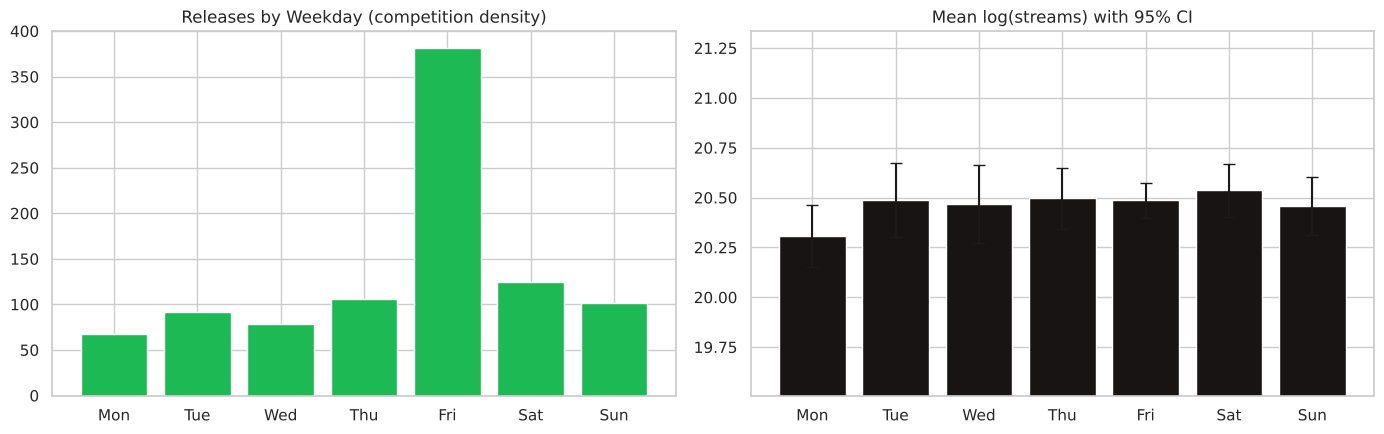

In [6]:
fig,ax = plt.subplots(1,2,figsize=(14,4.5))
ax[0].bar(DAYS, wd['releases'], color='#1DB954'); ax[0].set_title('Releases by Weekday (competition density)')
ax[1].bar(DAYS, wd['mean_log'], yerr=wd['ci95'], color='#191414', capsize=4); ax[1].set_title('Mean log(streams) with 95% CI')
ax[1].set_ylim(wd['mean_log'].min()-.8, wd['mean_log'].max()+.8); plt.tight_layout(); plt.show()

In [7]:
# 5b. Is the weekday difference statistically real? One-way ANOVA
groups = [x['log_streams'].values for _,x in tracks.groupby('weekday')]
F, p = stats.f_oneway(*groups)
print(f'ANOVA: F = {F:.3f}, p = {p:.4f} ->', 'significant weekday effect' if p<.05 else 'NO significant raw weekday effect')

ANOVA: F = 0.618, p = 0.7164 -> NO significant raw weekday effect


In [8]:
# 5c. Adjusted weekday effect: remove the influence of playlists, charts and track age first,
#     then look at what is left per weekday (like the OLS controls in the R analysis).
ctrl = ['in_spotify_playlists','in_spotify_charts','track_age_years']
Xc = tracks[ctrl].copy(); Xc['in_spotify_playlists'] = np.log1p(Xc['in_spotify_playlists'])
lr = LinearRegression().fit(Xc, tracks['log_streams'])
tracks['resid'] = tracks['log_streams'] - lr.predict(Xc)
adj = tracks.groupby('weekday')['resid'].agg(['mean','std','count'])
adj['ci95'] = stats.t.ppf(.975, adj['count']-1)*adj['std']/np.sqrt(adj['count']); adj.index = DAYS
adj[['mean','ci95']].round(4)

,mean,ci95
Mon,-0.1449,0.1180
Tue,-0.0194,0.1075
Wed,0.0187,0.1116
Thu,0.0153,0.0921
Fri,0.0412,0.0579
Sat,-0.0306,0.1011
Sun,-0.0342,0.1135


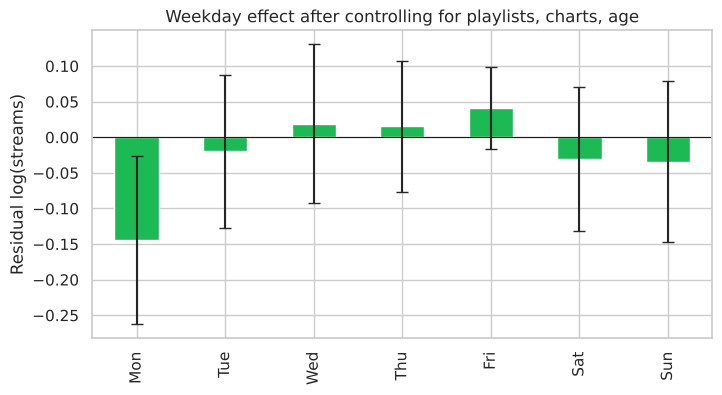

Best adjusted release day: Fri


In [9]:
adj['mean'].plot(kind='bar', yerr=adj['ci95'], color='#1DB954', capsize=4, figsize=(8,4))
plt.axhline(0,color='k',lw=.8); plt.title('Weekday effect after controlling for playlists, charts, age'); plt.ylabel('Residual log(streams)'); plt.show()
print('Best adjusted release day:', adj['mean'].idxmax())

## 6. Genre x Weekday demand (Spotify Historical Charts)

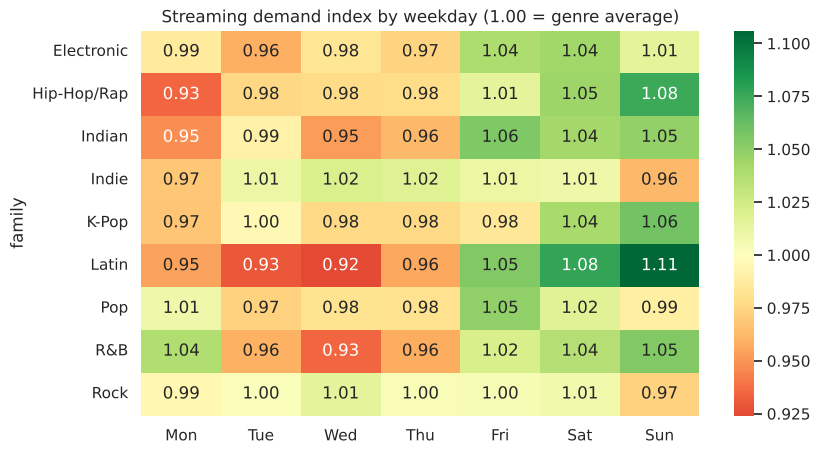

family
Electronic     Sat
Hip-Hop/Rap    Sun
Indian         Fri
Indie          Wed
K-Pop          Sun
Latin          Sun
Pop            Fri
R&B            Sun
Rock           Wed
dtype: str

In [10]:
def families(s):
    try: lst = ast.literal_eval(s) if isinstance(s,str) else list(s)
    except Exception: return []
    rules = [('k-pop','K-Pop'),('hip hop','Hip-Hop/Rap'),('rap','Hip-Hop/Rap'),('r&b','R&B'),('soul','R&B'),
             ('latin','Latin'),('reggaeton','Latin'),('bollywood','Indian'),('filmi','Indian'),('indian','Indian'),
             ('house','Electronic'),('edm','Electronic'),('electro','Electronic'),('dance','Electronic'),
             ('rock','Rock'),('metal','Rock'),('indie','Indie'),('pop','Pop')]
    out = set()
    for g in lst:
        for key,fam in rules:
            if key in g.lower(): out.add(fam); break
    return list(out)

charts['family'] = charts['artist_genres'].apply(families)
cg = charts.explode('family').dropna(subset=['family'])
gw = cg.groupby(['family','weekday'])['streams'].mean().unstack()
gw_index = gw.div(gw.mean(axis=1), axis=0)           # 1.00 = that genre's average day
gw_index.columns = DAYS
plt.figure(figsize=(9,5)); sns.heatmap(gw_index, annot=True, fmt='.2f', cmap='RdYlGn', center=1); plt.title('Streaming demand index by weekday (1.00 = genre average)'); plt.show()
best_day_by_genre = gw_index.idxmax(axis=1); best_day_by_genre

## 7. Best TIME of day: 168-hour listening matrix (Last.fm)

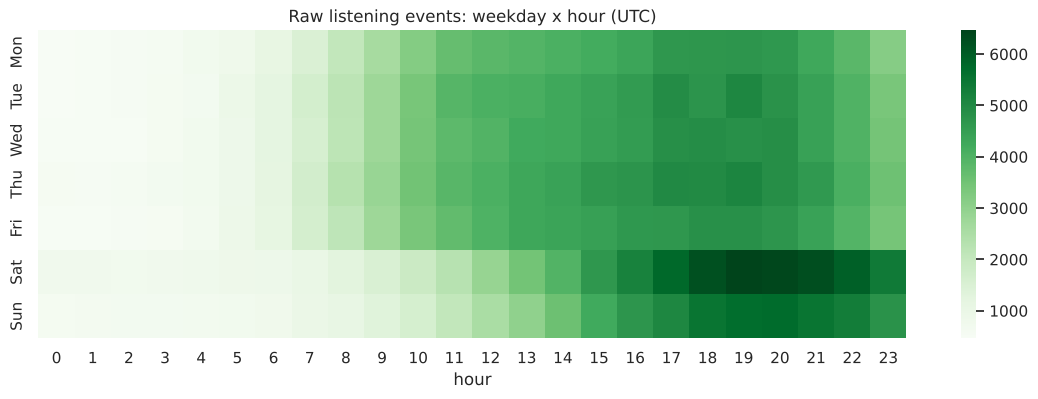

Peak hour overall: 19 :00 | Busiest weekday: Sat


In [11]:
lastfm['hour'] = lastfm['timestamp'].dt.hour
lastfm['weekday'] = lastfm['timestamp'].dt.dayofweek
lastfm['date'] = lastfm['timestamp'].dt.date
mat = lastfm.pivot_table(index='weekday', columns='hour', values='user_id', aggfunc='count').fillna(0)
mat.index = DAYS
plt.figure(figsize=(14,4)); sns.heatmap(mat, cmap='Greens'); plt.title('Raw listening events: weekday x hour (UTC)'); plt.show()
print('Peak hour overall:', int(mat.sum().idxmax()), ':00 | Busiest weekday:', mat.sum(axis=1).idxmax())

## 8. Random Forest: smooth the 168-hour activity curve
Raw counts per (date, hour) -> Random Forest learns the weekday x hour pattern -> predictions fill a clean 168-cell matrix.

In [12]:
hourly = lastfm.groupby(['date','weekday','hour']).size().reset_index(name='events')
hourly['hour_sin'] = np.sin(2*np.pi*hourly['hour']/24); hourly['hour_cos'] = np.cos(2*np.pi*hourly['hour']/24)
hourly['is_weekend'] = (hourly['weekday']>=5).astype(int)
fa = ['hour','weekday','is_weekend','hour_sin','hour_cos']
Xa, ya = hourly[fa], hourly['events']
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=.2, random_state=42)
rf_act = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(Xa_tr, ya_tr)
pa = rf_act.predict(Xa_te)
act_metrics = dict(MAE=float(mean_absolute_error(ya_te,pa)), RMSE=float(np.sqrt(mean_squared_error(ya_te,pa))), R2=float(r2_score(ya_te,pa)))
print({k:round(v,3) for k,v in act_metrics.items()})

{'MAE': 4.886, 'RMSE': 6.484, 'R2': 0.941}


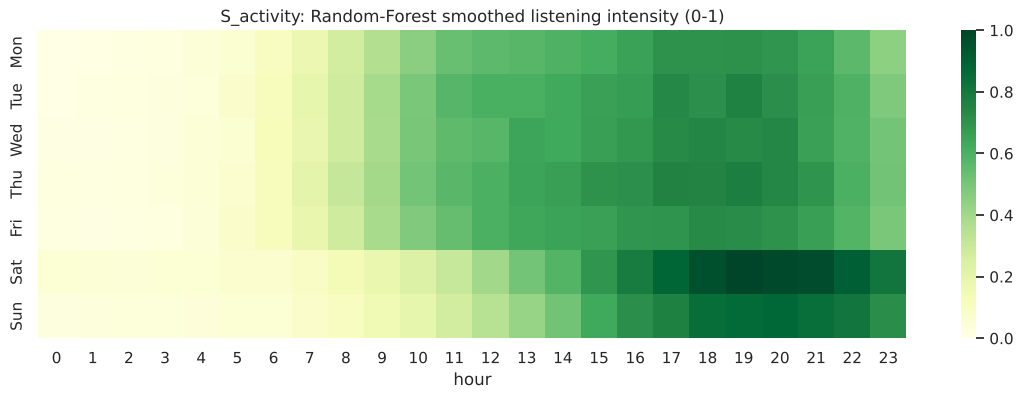

Best hour overall: 19 :00


In [13]:
grid = pd.DataFrame([(d,h) for d in range(7) for h in range(24)], columns=['weekday','hour'])
grid['hour_sin']=np.sin(2*np.pi*grid['hour']/24); grid['hour_cos']=np.cos(2*np.pi*grid['hour']/24); grid['is_weekend']=(grid['weekday']>=5).astype(int)
grid['pred_events'] = rf_act.predict(grid[fa])
act = grid.pivot(index='weekday', columns='hour', values='pred_events'); act.index = DAYS
S_activity = (act - act.values.min())/(act.values.max()-act.values.min())     # 0-1
plt.figure(figsize=(14,4)); sns.heatmap(S_activity, cmap='YlGn'); plt.title('S_activity: Random-Forest smoothed listening intensity (0-1)'); plt.show()
print('Best hour overall:', int(S_activity.sum().idxmax()), ':00')

## 9. Random Forest: does release weekday matter for streams? (Label Encoding)
Same flow as the reference notebook: select features -> split -> label-encode -> Random Forest -> metrics -> importance.

In [14]:
feat = ['weekday','released_month','released_year','is_weekend','artist_count','in_spotify_playlists','in_spotify_charts',
        'bpm','danceability_%','valence_%','energy_%','acousticness_%','speechiness_%','track_age_years']
X = tracks[feat].copy(); y = tracks['log_streams']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, random_state=42)
# fill missing
for c in X.columns: 
    m = Xtr[c].median(); Xtr[c]=Xtr[c].fillna(m); Xte[c]=Xte[c].fillna(m)
# label-encode the weekday label (kept as text) like the reference notebook
le = LabelEncoder(); day_names = Xtr['weekday'].map(dict(enumerate(DAYS)))
Xtr['weekday'] = le.fit_transform(day_names.astype(str))
mp = dict(zip(le.classes_, le.transform(le.classes_)))
Xte['weekday'] = Xte['weekday'].map(dict(enumerate(DAYS))).map(mp).fillna(-1)
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
pred = rf.predict(Xte)
mae, rmse, r2 = mean_absolute_error(yte,pred), np.sqrt(mean_squared_error(yte,pred)), r2_score(yte,pred)
print(f'MAE {mae:.3f} | RMSE {rmse:.3f} | R2 {r2:.3f}   (on log-streams)')

MAE 0.467 | RMSE 0.591 | R2 0.549   (on log-streams)


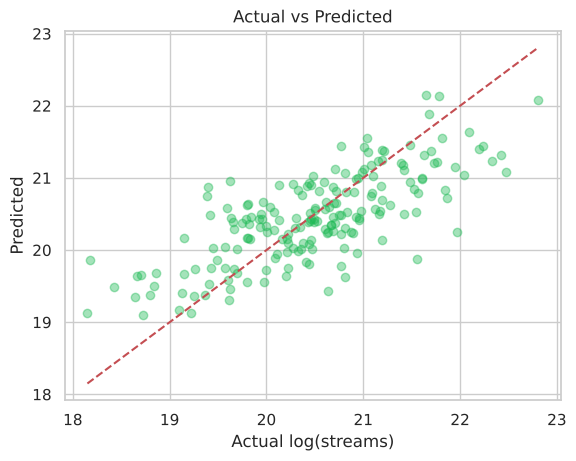

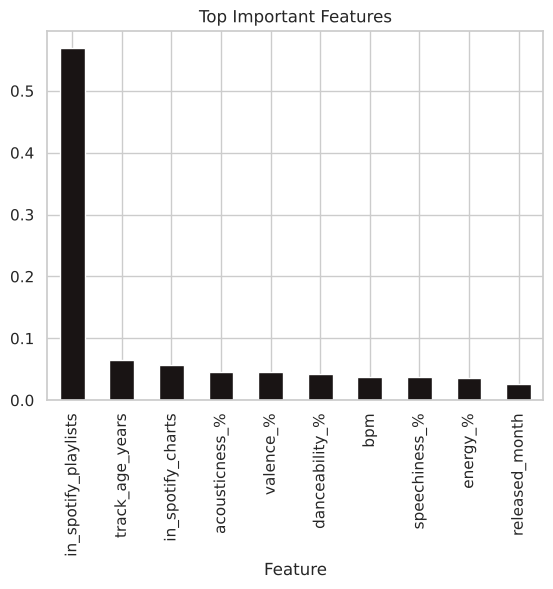

             Feature  Importance
in_spotify_playlists    0.568915
     track_age_years    0.065496
   in_spotify_charts    0.056573
      acousticness_%    0.046306
           valence_%    0.045119
      danceability_%    0.042045
                 bpm    0.038165
       speechiness_%    0.037700
            energy_%    0.035188
      released_month    0.026822


In [15]:
plt.scatter(yte, pred, alpha=.4, color='#1DB954'); plt.plot([yte.min(),yte.max()],[yte.min(),yte.max()],'r--')
plt.xlabel('Actual log(streams)'); plt.ylabel('Predicted'); plt.title('Actual vs Predicted'); plt.show()
imp = pd.DataFrame({'Feature':Xtr.columns,'Importance':rf.feature_importances_}).sort_values('Importance',ascending=False)
imp.head(10).plot(x='Feature', y='Importance', kind='bar', legend=False, color='#191414'); plt.title('Top Important Features'); plt.show()
print(imp.head(10).to_string(index=False))

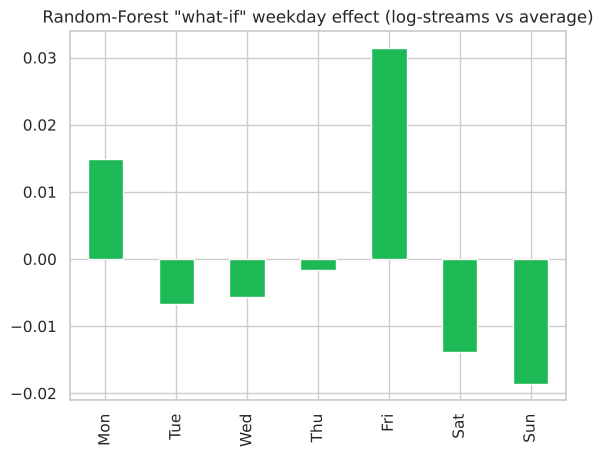

Mon    0.0149
Tue   -0.0067
Wed   -0.0057
Thu   -0.0016
Fri    0.0315
Sat   -0.0139
Sun   -0.0186
dtype: float64

In [16]:
# Model-based weekday effect: predict the SAME tracks as if they were released on each weekday
base = Xte.copy(); eff = {}
for i,d in enumerate(DAYS):
    t = base.copy(); t['weekday'] = mp.get(d,-1); t['is_weekend'] = int(i>=5)
    eff[d] = rf.predict(t).mean()
eff = pd.Series(eff); eff_rel = eff - eff.mean()
eff_rel.plot(kind='bar', color='#1DB954'); plt.title('Random-Forest "what-if" weekday effect (log-streams vs average)'); plt.show()
eff_rel.round(4)

## 10. Release Score = Activity x Day Performance x Low Competition
For every (weekday, hour):

`Release_Score = 0.50 * S_activity + 0.30 * S_day_performance + 0.20 * (1 - S_competition)`

- **S_activity**: Random-Forest smoothed Last.fm listening intensity
- **S_day_performance**: blend of adjusted release-day effect (Spotify 2023) and, if a genre is chosen, that genre's weekday demand (Charts)
- **S_competition**: share of releases landing on that weekday (crowded = worse)

The weights are a **modelling assumption**; section 11 tests how sensitive the answer is to them.

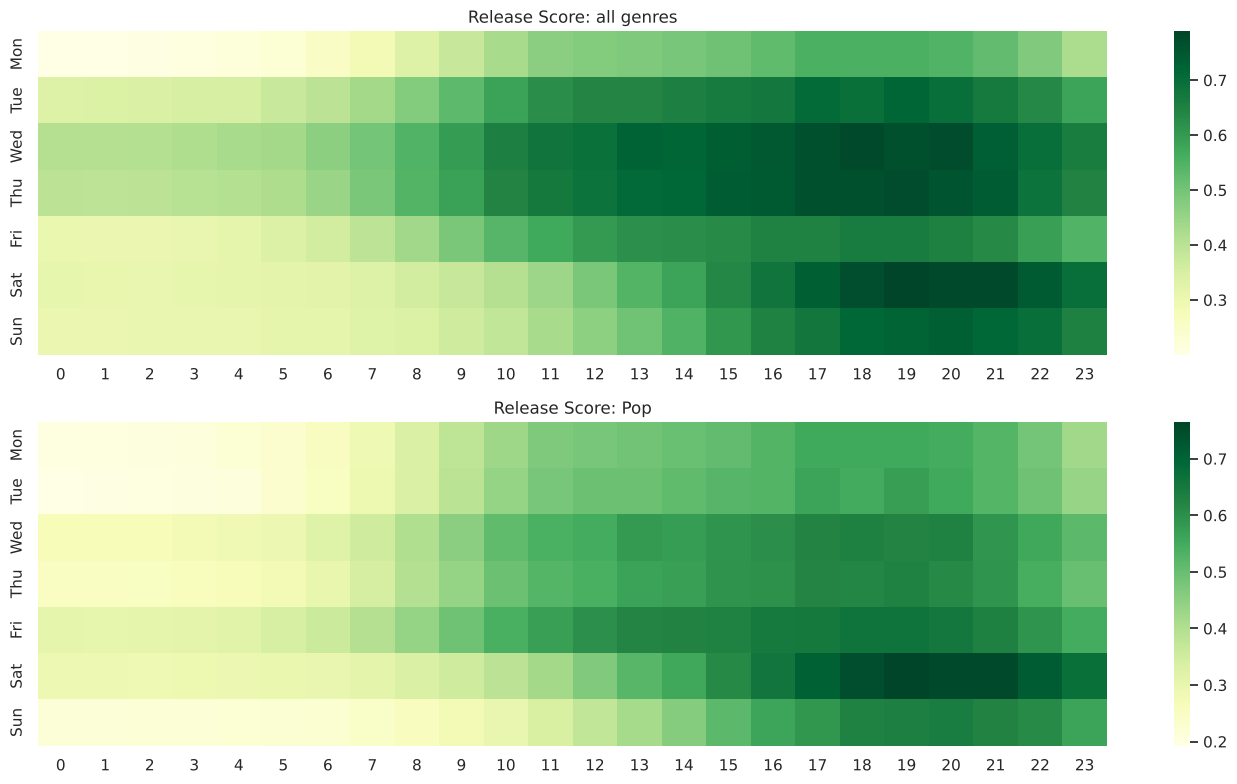

TOP 5 - all genres
Day  Hour  Score
Sat 19:00  0.789
Sat 20:00  0.779
Wed 18:00  0.776
Sat 21:00  0.776
Thu 19:00  0.775

TOP 5 - Pop
Day  Hour  Score
Sat 19:00  0.765
Sat 20:00  0.754
Sat 21:00  0.752
Sat 18:00  0.746
Sat 22:00  0.717


In [17]:
mm = lambda s: (s-s.min())/(s.max()-s.min())
S_comp = mm(wd['release_share'])
S_perf_global = mm((adj['mean'] + eff_rel)/2)            # two independent views of the weekday effect
def day_perf(genre=None):
    if genre and genre in gw_index.index: return mm((S_perf_global + mm(gw_index.loc[genre]))/2)
    return S_perf_global

def release_matrix(genre=None, w=(.5,.3,.2)):
    dp = day_perf(genre)
    M = pd.DataFrame({h: w[0]*S_activity[h] + w[1]*dp + w[2]*(1-S_comp) for h in range(24)})
    return M.round(4)

R_all, R_gen = release_matrix(), release_matrix(OUR_GENRE)
fig,ax = plt.subplots(2,1,figsize=(14,8))
sns.heatmap(R_all, cmap='YlGn', ax=ax[0]); ax[0].set_title('Release Score: all genres')
sns.heatmap(R_gen, cmap='YlGn', ax=ax[1]); ax[1].set_title(f'Release Score: {OUR_GENRE}'); plt.tight_layout(); plt.show()

def top_windows(M, k=5):
    s = M.stack().sort_values(ascending=False).head(k)
    return pd.DataFrame([{'Day':d,'Hour':f'{h:02d}:00','Score':round(v,3)} for (d,h),v in s.items()])
print('TOP 5 - all genres'); print(top_windows(R_all).to_string(index=False))
print(f'\nTOP 5 - {OUR_GENRE}'); print(top_windows(R_gen).to_string(index=False))

## 11. Robustness: does the answer survive different weights?

In [18]:
import itertools
combos = [(a,b,round(1-a-b,2)) for a in np.arange(.2,.81,.1) for b in np.arange(.1,.61,.1) if 1-a-b>=.05]
def best_day_hour(M):
    d = M.apply(lambda r: r.nlargest(5).mean(), axis=1).idxmax(); return (d, int(M.loc[d].idxmax()))
wins = pd.Series([ best_day_hour(release_matrix(OUR_GENRE, c)) for c in combos ])
share = wins.value_counts(normalize=True).head(5)
print(f'{len(combos)} weight combinations tested. Winning (day, hour) frequency:')
print(share.round(3).to_string())
best_day_votes = pd.Series([w[0] for w in wins]).value_counts(normalize=True)
print('\nBest DAY frequency:'); print(best_day_votes.round(3).to_string())
print('\nBest HOUR frequency:'); print(pd.Series([w[1] for w in wins]).value_counts(normalize=True).round(3).to_string())

27 weight combinations tested. Winning (day, hour) frequency:
(Sat, 19)    0.667
(Fri, 18)    0.222
(Wed, 18)    0.111

Best DAY frequency:
Sat    0.667
Fri    0.222
Wed    0.111

Best HOUR frequency:
19    0.667
18    0.333


## 12. Sanity-check on your own catalog (Sample Artist Releases)

In [19]:
cat = catalog.copy()
cat['release_datetime_local'] = pd.to_datetime(cat['release_datetime_local'])
cat['weekday'] = cat['release_datetime_local'].dt.dayofweek; cat['hour'] = cat['release_datetime_local'].dt.hour
cat['slot_score'] = [R_all.loc[DAYS[d], h] for d,h in zip(cat['weekday'], cat['hour'])]
r = cat[['slot_score','streams_first_7_days']].corr(method='spearman').iloc[0,1]
print(f'Spearman correlation (slot score vs first-7-day streams), n={len(cat)}: {r:.3f}')
print('Small sample: treat as a directional check only.'); cat[['track_title','weekday','hour','slot_score','streams_first_7_days']].head()

Spearman correlation (slot score vs first-7-day streams), n=22: 0.134
Small sample: treat as a directional check only.


,track_title,weekday,hour,slot_score,streams_first_7_days
0,Electronic Sample Track 01,3,8,0.5439,354972
1,Pop Sample Track 02,0,14,0.4972,356855
2,R&B Sample Track 03,6,18,0.7177,514583
3,R&B Sample Track 04,1,8,0.4800,585999
4,Pop Sample Track 05,4,8,0.4398,251367


## 13. Final Recommendation

In [20]:
bd_all = R_all.stack().idxmax(); bd_gen = R_gen.stack().idxmax()
# Best DAY = the day whose 5 best hours score highest (prime-time), so day and hour recommendations agree
prime = lambda M: M.apply(lambda r: r.nlargest(5).mean(), axis=1)
day_all, day_gen = prime(R_all).idxmax(), prime(R_gen).idxmax()
hr_all, hr_gen = int(R_all.loc[day_all].idxmax()), int(R_gen.loc[day_gen].idxmax())
print(f'BEST DAY  (all genres): {day_all} at {hr_all:02d}:00')
print(f'BEST DAY  ({OUR_GENRE}): {day_gen} at {hr_gen:02d}:00')
print('Prime-time score by day:'); print(prime(R_gen).round(3).to_string())
print('Best 3-hour window that day:', ', '.join(f'{h:02d}:00' for h in R_gen.loc[day_gen].nlargest(3).index.sort_values()))
print('Release 1-2 h BEFORE the peak so the track is live when the audience arrives.')
if USING_SYNTHETIC: print('\n[!] Some inputs were SYNTHETIC. Re-run with the real datasets before presenting numbers.')

BEST DAY  (all genres): Sat at 19:00
BEST DAY  (Pop): Sat at 19:00
Prime-time score by day:
Mon    0.547
Tue    0.553
Wed    0.623
Thu    0.616
Fri    0.655
Sat    0.747
Sun    0.628
Best 3-hour window that day: 19:00, 20:00, 21:00
Release 1-2 h BEFORE the peak so the track is live when the audience arrives.

[!] Some inputs were SYNTHETIC. Re-run with the real datasets before presenting numbers.


## 14. Export for the Website

In [21]:
def mat_list(M): return [[round(float(M.loc[d,h]),4) for h in range(24)] for d in DAYS]
S_activity.round(4).to_csv('outputs/activity_matrix_168.csv'); R_all.set_index(pd.Index(DAYS)).to_csv('outputs/release_score_all.csv')
R_gen.set_index(pd.Index(DAYS)).to_csv('outputs/release_score_genre.csv'); gw_index.round(4).to_csv('outputs/genre_weekday_index.csv')
wd.round(4).to_csv('outputs/weekday_performance.csv'); imp.to_csv('outputs/feature_importance.csv', index=False)
pd.DataFrame({'Model':['RF release-day (log streams)','RF activity curve'],
  'MAE':[mae,act_metrics['MAE']],'RMSE':[rmse,act_metrics['RMSE']],'R2':[r2,act_metrics['R2']]}).to_csv('outputs/model_metrics.csv', index=False)

site = dict(
  meta=dict(project='Spotify Listener Behaviour Analysis & Release-Window Advisor', default_genre=OUR_GENRE,
            synthetic_inputs=bool(USING_SYNTHETIC), days=DAYS, hours=list(range(24)), weights=dict(activity=.5, day_performance=.3, low_competition=.2),
            datasets=dict(tracks=int(len(tracks)), listening_events=int(len(lastfm)), chart_rows=int(len(charts)), catalog=int(len(catalog)))),
  recommendation=dict(all_genres=dict(best_day=day_all, best_hour=hr_all, best_slot=dict(day=bd_all[0], hour=int(bd_all[1]))),
                      genre=dict(name=OUR_GENRE, best_day=day_gen, best_hour=int(hr_gen), best_slot=dict(day=bd_gen[0], hour=int(bd_gen[1])), prime_time_by_day={d: round(float(v),4) for d,v in prime(R_gen).items()})),
  top_windows_all=top_windows(R_all,10).to_dict('records'),
  weekday_performance=dict(releases=wd['releases'].tolist(), mean_log_streams=wd['mean_log'].round(4).tolist(), ci95=wd['ci95'].round(4).tolist(),
                           median_streams_millions=wd['median_streams_M'].round(2).tolist(), release_share=wd['release_share'].round(4).tolist(),
                           adjusted_effect=adj['mean'].round(4).tolist(), adjusted_ci95=adj['ci95'].round(4).tolist(), anova=dict(F=round(F,3), p=round(float(p),4))),
  components=dict(S_activity=mat_list(S_activity), S_competition=[round(float(x),4) for x in S_comp],
                  S_day_perf_global=[round(float(x),4) for x in S_perf_global],
                  S_day_perf_by_genre={g:[round(float(x),4) for x in day_perf(g)] for g in gw_index.index}),
  activity_matrix=mat_list(S_activity), release_score_all=mat_list(R_all),
  release_score_by_genre={g: mat_list(release_matrix(g)) for g in gw_index.index},
  genre_weekday_index={g: gw_index.loc[g].round(4).tolist() for g in gw_index.index},
  best_day_by_genre=best_day_by_genre.to_dict(),
  models=dict(release_day=dict(MAE=round(mae,4),RMSE=round(rmse,4),R2=round(r2,4)), activity=dict({k:round(v,4) for k,v in act_metrics.items()})),
  feature_importance=imp.head(10).round(4).to_dict('records'),
  robustness=dict(best_day_frequency=best_day_votes.round(3).to_dict(), combos_tested=len(combos)),
  limitations=['Spotify 2023 has no release hour; hour comes from Last.fm listening behaviour.','Last.fm users are not the whole Spotify audience.',
               'Charts only contain Top-200 tracks (selection bias).','Score weights are a modelling assumption; see robustness.',
               'Stream counts are cumulative, so track age is controlled for.'])
json.dump(site, open('outputs/website_data.json','w'), indent=2)
print('Saved:', sorted(os.listdir('outputs')))

Saved: ['activity_matrix_168.csv', 'feature_importance.csv', 'genre_weekday_index.csv', 'model_metrics.csv', 'release_score_all.csv', 'release_score_genre.csv', 'website_data.json', 'weekday_performance.csv']


## 15. Website Dashboard
Load `outputs/website_data.json` in the website (see the master prompt). Suggested pages:

**KPI cards:** Best Day | Best Hour | Best Slot | Genre | Model R²
**Charts:** Weekday performance with CI | 168-hour activity heatmap | Release-score heatmap | Genre x weekday heatmap | Feature importance | Robustness bars
**Interactive:** genre dropdown -> recalculates best day/time | timezone shift | weight sliders